# Beat bônus: Contrafactual — e a evidência *contra*?

**Pergunta:** e a evidência **contra** a classe?

**Tempo:** 1 min. Fora dos 10 beats — é o primeiro item da lista de corte.
Este notebook fecha a Fase 7 e prepara o terreno de
[`08_numeros`](08_numeros.ipynb): se o Grad-CAM mostra onde a rede *vê* a
classe, negar `α` em (1) mostra onde ela vê o contrário.

In [6]:
import os
import sys

sys.path.append(os.path.abspath('.'))
sys.path.append(os.path.abspath('notebooks'))

import torch
import matplotlib.pyplot as plt
from PIL import Image

from gradcam import counterfactual, gradcam
from gradcam.metrics import spearman
from gradcam.models import (
    imagenet_labels,
    load_model,
    preprocess,
    resolve_class,
    denormalize,
)
from gradcam.viz import figure_grid, overlay, tensor_to_numpy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model("vgg16", device=device)
labels = imagenet_labels()
print(f"VGG-16 carregado em {device} | {len(labels)} classes ImageNet")

VGG-16 carregado em cpu | 1000 classes ImageNet


## A conta muda em uma linha

O Grad-CAM de (1)–(2) usa `α_k^c = (1/Z) Σ_ij ∂y^c/∂A^k_ij`. O contrafactual
troca o sinal **antes** do ReLU:

```python
alpha  = grad.mean(dim=(2, 3), keepdim=True)      # Grad-CAM
contra = (-alpha * activations).sum(dim=1)[0]     # contrafactual
```

O ReLU de (2) continua igual: sem ele, a combinação negativa mostraria também
as regiões neutras. Toda a lógica vive em `gradcam.counterfactual` — a célula
abaixo só chama a biblioteca, como manda a regra 1 do plano.

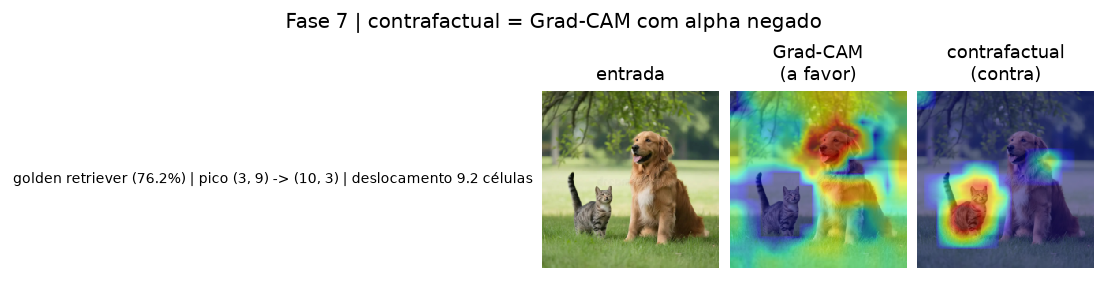

mapa 14x14 | Spearman(a favor, contra) = -0.675
pico a favor (3, 9) -> contra (10, 3) | deslocamento 9.2 células


In [7]:
base = "notebooks/assets" if os.path.isdir("notebooks/assets") else "assets"
image = Image.open(os.path.join(base, "cat_dog.jpg")).convert("RGB")
x = preprocess(image)
image_rgb = tensor_to_numpy(denormalize(x))

# A escala de exibição é decisão fixa do plano (nunca de métrica).
DISPLAY_HIGH, DISPLAY_GAMMA = 0.99, 0.5

class_idx = resolve_class("golden retriever", labels)
probs = torch.softmax(model(x)[0], dim=0)

for_map, _ = gradcam(model, x, class_idx)
against_map, _ = counterfactual(model, x, class_idx)

height, width = for_map.shape
peak_for = divmod(int(for_map.argmax()), width)
peak_against = divmod(int(against_map.argmax()), width)
dy, dx = peak_against[0] - peak_for[0], peak_against[1] - peak_for[1]
shift = (dy * dy + dx * dx) ** 0.5
rho = spearman(for_map, against_map)

fig = figure_grid(
    [[
        image_rgb,
        overlay(image_rgb, for_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
        overlay(image_rgb, against_map, high=DISPLAY_HIGH, gamma=DISPLAY_GAMMA),
    ]],
    col_titles=("entrada", "Grad-CAM\n(a favor)", "contrafactual\n(contra)"),
    row_titles=[
        f"{labels[class_idx]} ({probs[class_idx]:.1%}) | "
        f"pico {peak_for} -> {peak_against} | "
        f"deslocamento {shift:.1f} células"
    ],
    suptitle="Fase 7 | contrafactual = Grad-CAM com alpha negado",
)
plt.show()

print(f"mapa {height}x{width} | Spearman(a favor, contra) = {rho:+.3f}")
print(f"pico a favor {peak_for} -> contra {peak_against} | deslocamento {shift:.1f} células")

**O mapa sai do objeto da classe.** O pico se desloca e o Spearman tende a ficar
negativo: negar `α` inverte o sinal da combinação antes do ReLU, então onde o
mapa a favor é claro o contra tende a ser escuro. Mas os dois passam por ReLUs
separados, então a ordenação final não é o negativo exato do outro mapa — o que
se lê é o **deslocamento**, não a correlação.

Cuidado com a expectativa: o contrafactual **não** é o mapa da outra classe. Ele
acende o que reduz `y^c` — bordas, fundo, objetos vizinhos —, e em geral não
reproduz o mapa que a classe vizinha teria. Na imagem de dois objetos do COCO
(`95786`, copo e vaso) o deslocamento é de ~9 células de 14 e o efeito é o mesmo.

In [8]:
metrics_path = os.path.join("results", "metrics", "counterfactual.json")
if not os.path.exists(metrics_path):
    metrics_path = os.path.join("..", "results", "metrics", "counterfactual.json")

import json

with open(metrics_path, "r", encoding="utf-8") as handle:
    measured = json.load(handle)

for run in measured["runs"]:
    for_peak = (run["peak_gradcam"]["y"], run["peak_gradcam"]["x"])
    cf_peak = (run["peak_counterfactual"]["y"], run["peak_counterfactual"]["x"])
    print(
        f"{run['class']:>5} | prob {run['prob']:6.1%} | "
        f"pico {for_peak} -> {cf_peak} | "
        f"{run['shift_cells']:.1f} células ({run['shift_px']:.0f} px) | "
        f"rho {run['spearman_gradcam_counterfactual']:+.3f}"
    )
print(f"\nfonte: {metrics_path} (script 07_counterfactual.py)")

  cup | prob  21.8% | pico (10, 9) -> (13, 0) | 9.5 células (152 px) | rho -0.605
 vase | prob   1.3% | pico (2, 9) -> (11, 7) | 9.2 células (148 px) | rho -0.546

fonte: ..\results\metrics\counterfactual.json (script 07_counterfactual.py)


**Takeaway:** negar `α` em (1) é uma linha de código e uma pergunta diferente —
não é uma explicação melhor, é a explicação do contrário. Na Fase 8 ele não entra
na bateria: as métricas de localização do paper comparam métodos que respondem
"onde está a classe", e o contrafactual responde outra coisa.

Fonte dos números: `results/metrics/counterfactual.json` (não há valor digitado à
mão). Linha correspondente do README: status da Fase 7.